# Customer Churn Prediction (Telco)
**Goal:** predict which telecom customers are likely to leave, understand *why*, and give the business an action plan.

**Pipeline:** Cleaning → EDA → Feature engineering → Model comparison → Tuning → Threshold selection → Test evaluation → SHAP explainability → Save model for Streamlit.

**Why recall matters here:** missing a churner (false negative) costs a customer's lifetime revenue; a wasted retention offer (false positive) costs a small discount. So we care about catching churners, balanced with precision.

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib, shap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve, precision_recall_curve, recall_score, precision_score, f1_score)
from xgboost import XGBClassifier

from features import add_features

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 1. Load data

In [2]:
df = pd.read_csv("data/Telco-Customer-Churn.csv")
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()
print("\nDuplicates:", df.duplicated().sum())
print("TotalCharges blanks:", (df['TotalCharges'].str.strip() == '').sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 2. Cleaning
- `TotalCharges` is stored as text; blanks belong to customers with `tenure = 0` (brand-new), so we fill them with 0 (done inside `features.add_features`).
- `customerID` has no predictive value, so we drop it.
- Target `Churn` → 1/0.

In [4]:
data = df.drop(columns=["customerID"]).copy()
data["Churn"] = (data["Churn"] == "Yes").astype(int)
print("Churn rate:", round(data["Churn"].mean(), 3))
data["Churn"].value_counts()

Churn rate: 0.265


Churn
0    5174
1    1869
Name: count, dtype: int64

## 3. Exploratory Data Analysis

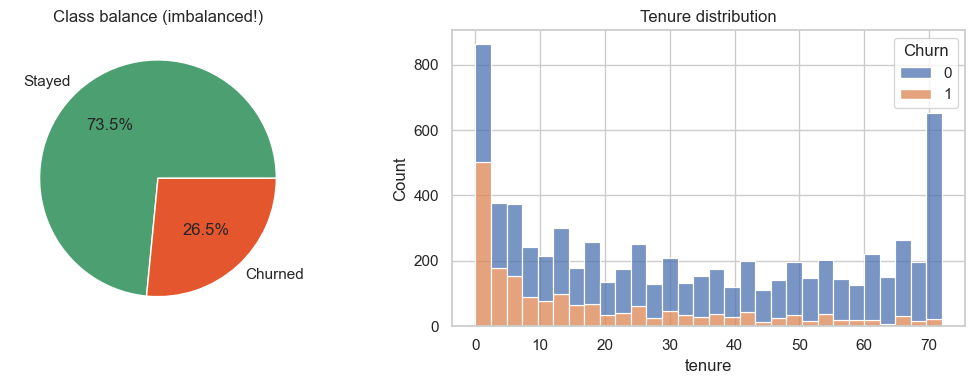

In [5]:
eda = add_features(data)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
eda["Churn"].value_counts().plot.pie(autopct="%1.1f%%", labels=["Stayed", "Churned"], ax=ax[0], colors=["#4C9F70", "#E4572E"])
ax[0].set_ylabel(""); ax[0].set_title("Class balance (imbalanced!)")
sns.histplot(data=eda, x="tenure", hue="Churn", bins=30, multiple="stack", ax=ax[1])
ax[1].set_title("Tenure distribution")
plt.tight_layout(); plt.savefig("images/01_balance_tenure.png", dpi=120); plt.show()

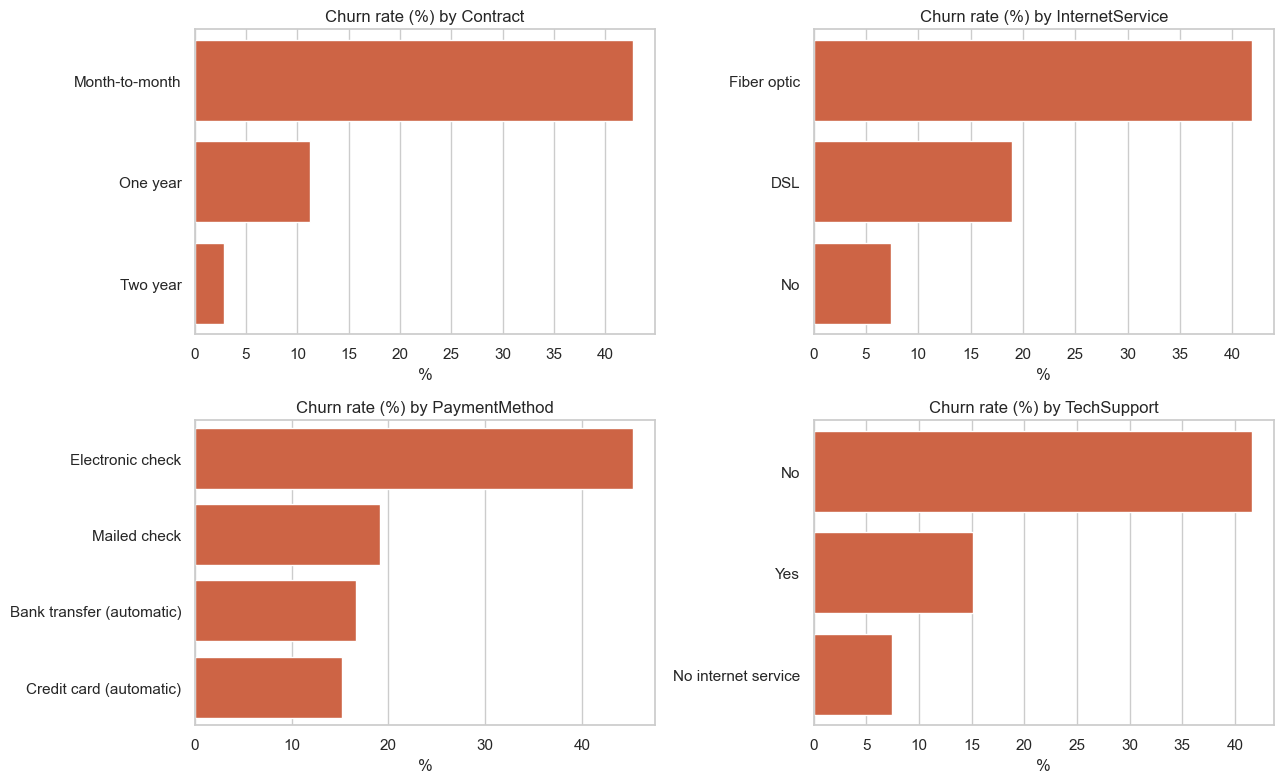

In [6]:
cols = ["Contract", "InternetService", "PaymentMethod", "TechSupport"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for a, c in zip(axes.ravel(), cols):
    rate = eda.groupby(c)["Churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=a, color="#E4572E")
    a.set_title(f"Churn rate (%) by {c}"); a.set_xlabel("%"); a.set_ylabel("")
plt.tight_layout(); plt.savefig("images/02_churn_by_category.png", dpi=120); plt.show()

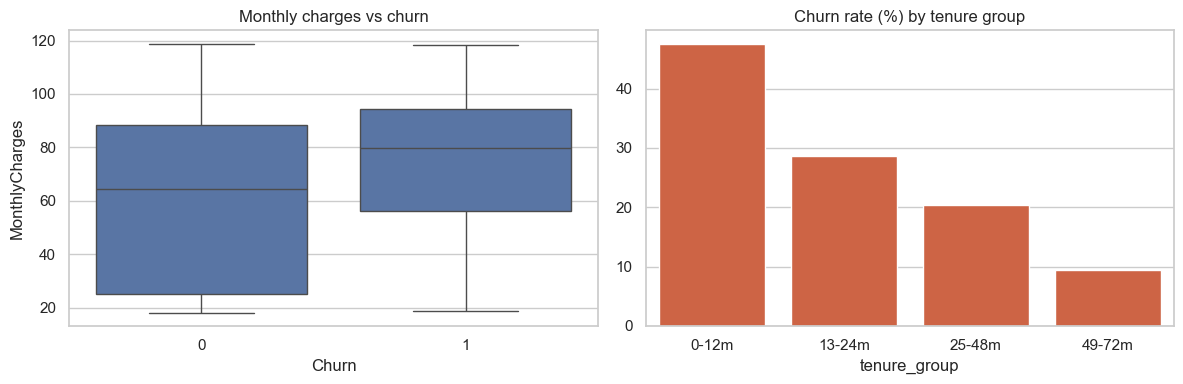

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=eda, x="Churn", y="MonthlyCharges", ax=ax[0]); ax[0].set_title("Monthly charges vs churn")
rate = eda.groupby("tenure_group")["Churn"].mean().reindex(["0-12m","13-24m","25-48m","49-72m"]) * 100
sns.barplot(x=rate.index, y=rate.values, ax=ax[1], color="#E4572E"); ax[1].set_title("Churn rate (%) by tenure group")
plt.tight_layout(); plt.savefig("images/03_charges_tenure.png", dpi=120); plt.show()

**What to write down here (in your own words, using your charts):** which contract type, internet service, payment method and tenure band churn the most? These observations become your business recommendations at the end.

## 4. Train/test split + preprocessing pipeline
We split **first** (stratified), then everything else is learned from the training set only: no data leakage.
The pipeline = feature engineering → one-hot encode categoricals + scale numerics → model.

In [8]:
X = data.drop(columns="Churn")
y = data["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

def make_pipeline(model):
    prep = ColumnTransformer([
        ("num", StandardScaler(), make_column_selector(dtype_include="number")),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), make_column_selector(dtype_exclude="number")),
    ])
    return Pipeline([("features", FunctionTransformer(add_features)), ("prep", prep), ("model", model)])

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", round(pos_weight, 2))

(5634, 19) (1409, 19)
scale_pos_weight: 2.77


## 5. Compare models (5-fold stratified cross-validation)
Imbalance is handled with class weights (leak-free, no resampling needed). Accuracy is misleading here, so we compare ROC-AUC, recall, precision and F1.

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, scale_pos_weight=pos_weight,
                             eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, m in models.items():
    r = cross_validate(make_pipeline(m), X_train, y_train, cv=cv,
                       scoring=["roc_auc", "recall", "precision", "f1"])
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in ["roc_auc", "recall", "precision", "f1"]}})
cv_results = pd.DataFrame(rows).set_index("model").round(3)
cv_results

,roc_auc,recall,precision,f1
model,,,,
Logistic Regression,0.846,0.794,0.516,0.625
Random Forest,0.844,0.712,0.560,0.627
XGBoost,0.843,0.773,0.531,0.630


## 6. Hyperparameter tuning (XGBoost, optimising ROC-AUC)

In [10]:
param_dist = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [2, 3, 4, 5],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
    "model__min_child_weight": [1, 3, 5],
}
search = RandomizedSearchCV(make_pipeline(models["XGBoost"]), param_dist, n_iter=25, scoring="roc_auc",
                            cv=cv, random_state=RANDOM_STATE, n_jobs=-1, verbose=0)
search.fit(X_train, y_train)
print("Best CV ROC-AUC:", round(search.best_score_, 4))
print(search.best_params_)
best_pipe = search.best_estimator_

Best CV ROC-AUC: 0.8496
{'model__subsample': 1.0, 'model__n_estimators': 500, 'model__min_child_weight': 3, 'model__max_depth': 3, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.6}


## 7. Choose the decision threshold (using training data only)
The default 0.5 cut-off isn't optimal for imbalanced data. We get out-of-fold probabilities on the **training** set and pick the threshold that maximises F1. The test set stays untouched until the final evaluation.

Chosen threshold: 0.56


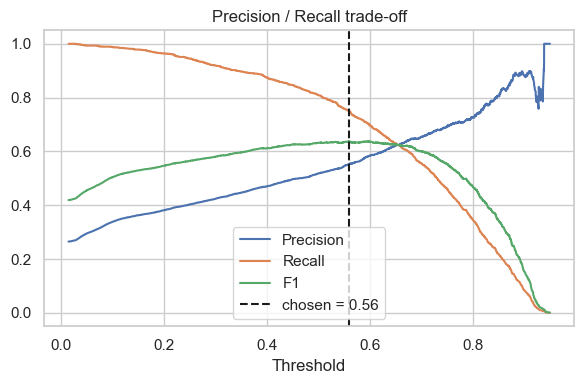

In [11]:
oof = cross_val_predict(best_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = float(thr[np.argmax(f1s[:-1])])
print("Chosen threshold:", round(best_thr, 3))

plt.figure(figsize=(6, 4))
plt.plot(thr, prec[:-1], label="Precision"); plt.plot(thr, rec[:-1], label="Recall"); plt.plot(thr, f1s[:-1], label="F1")
plt.axvline(best_thr, color="k", ls="--", label=f"chosen = {best_thr:.2f}")
plt.xlabel("Threshold"); plt.legend(); plt.title("Precision / Recall trade-off")
plt.tight_layout(); plt.savefig("images/04_threshold.png", dpi=120); plt.show()

## 8. Final evaluation on the held-out test set

              precision    recall  f1-score   support

      Stayed       0.90      0.77      0.83      1035
     Churned       0.55      0.76      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77      0.78      1409

ROC-AUC: 0.846


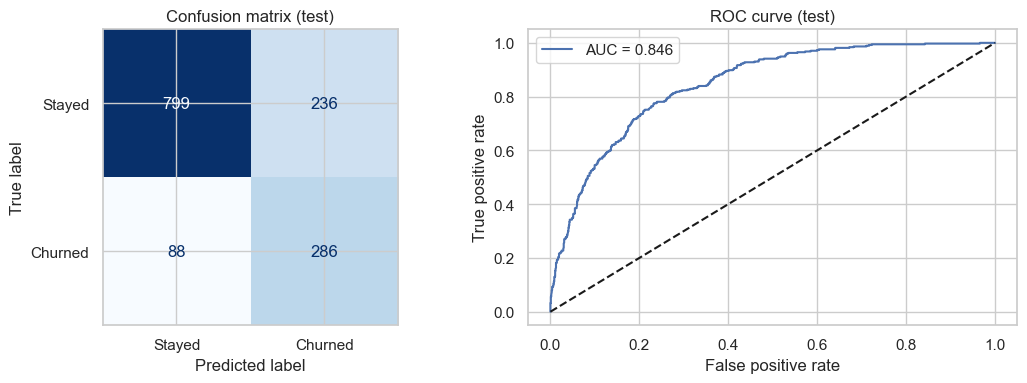

In [12]:
proba = best_pipe.predict_proba(X_test)[:, 1]
pred = (proba >= best_thr).astype(int)

print(classification_report(y_test, pred, target_names=["Stayed", "Churned"]))
auc = roc_auc_score(y_test, proba)
print("ROC-AUC:", round(auc, 3))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed", "Churned"]).plot(ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("Confusion matrix (test)")
fpr, tpr, _ = roc_curve(y_test, proba)
ax[1].plot(fpr, tpr, label=f"AUC = {auc:.3f}"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(); ax[1].set_title("ROC curve (test)")
plt.tight_layout(); plt.savefig("images/05_evaluation.png", dpi=120); plt.show()

## 9. Explainability with SHAP
Which features push a customer towards churning, and by how much?

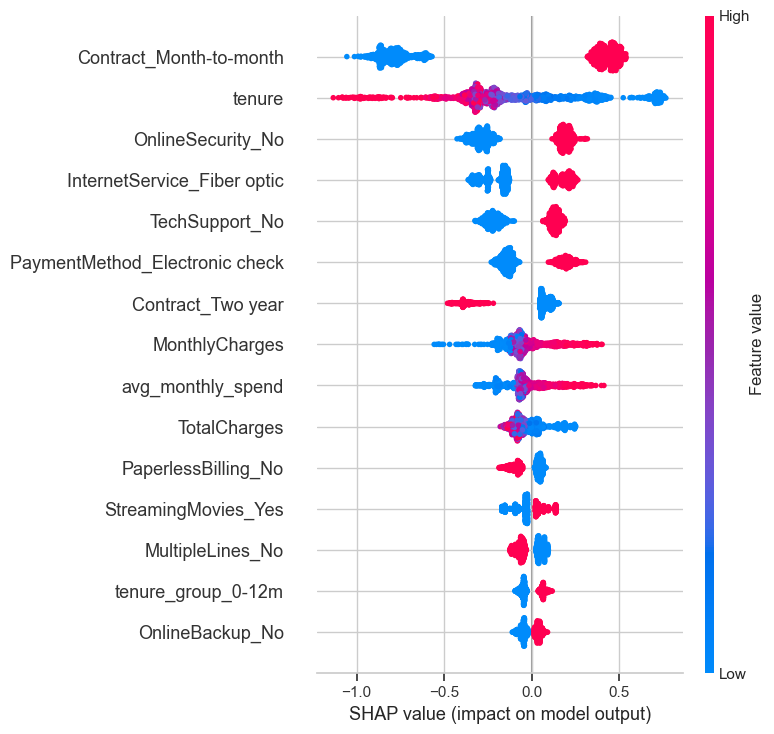

In [13]:
prep = best_pipe.named_steps["prep"]
Xt = best_pipe[:-1].transform(X_test)
names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]
Xt = pd.DataFrame(Xt, columns=names)

explainer = shap.TreeExplainer(best_pipe.named_steps["model"])
sv = explainer.shap_values(Xt)

plt.figure()
shap.summary_plot(sv, Xt, show=False, max_display=15)
plt.tight_layout(); plt.savefig("images/06_shap_summary.png", dpi=120, bbox_inches="tight"); plt.show()

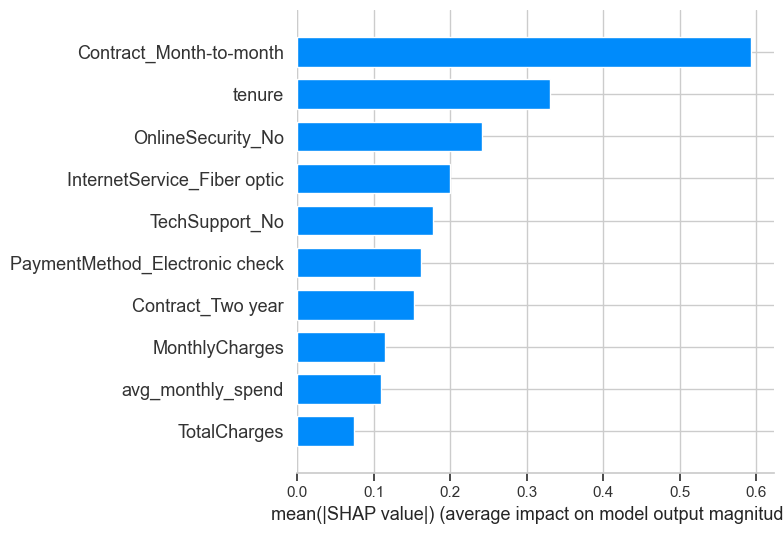

In [14]:
plt.figure()
shap.summary_plot(sv, Xt, plot_type="bar", show=False, max_display=10)
plt.tight_layout(); plt.savefig("images/07_shap_bar.png", dpi=120, bbox_inches="tight"); plt.show()

## 10. Save the model for the Streamlit app

In [15]:
joblib.dump(best_pipe, "model/churn_pipeline.joblib")
meta = {
    "model_name": "XGBoost (tuned)",
    "threshold": best_thr,
    "test_roc_auc": float(auc),
    "test_recall": float(recall_score(y_test, pred)),
    "test_precision": float(precision_score(y_test, pred)),
    "test_f1": float(f1_score(y_test, pred)),
}
json.dump(meta, open("model/metadata.json", "w"), indent=2)
meta

{'model_name': 'XGBoost (tuned)',
 'threshold': 0.560077965259552,
 'test_roc_auc': 0.8462838099666744,
 'test_recall': 0.7647058823529411,
 'test_precision': 0.5478927203065134,
 'test_f1': 0.6383928571428571}

## 11. Business insights & recommendations
**.Retention targeting:** the model has 0.76 recall, so it catches about 3 in 4 churners. Retention offers can go to the customers it flags as high risk rather than to everyone.

**.Cost trade-off:** you chose a threshold to balance precision and recall. A wasted discount costs less than losing a customer, which is why recall matters here.

**.Caveat:** these are patterns in the data, not proof of cause. You’d confirm them with an A/B test of retention offers.